# 价值指数 · 逐表数据可视化分析

基于国家统计局「数据库 — 季度数据」对**价值指数**主题的 5 张数据表逐一进行可视化分析。

| # | 数据表 | 时间范围 | 分析内容 |
| --- | --- | --- | --- |
| 1 | 农产品生产者价格指数（上年同期=100） | 2025Q2—2026Q3 当季 | 总指数与主要品类走势、分类涨跌发散图 |
| 2 | 固定资产投资价格指数_当季（-2018 旧口径） | 2017Q4—2018Q4 | 总指数与主要分项走势、分类涨跌发散图 |
| 3 | 固定资产投资价格指数_当季（2019- 新口径） | 2019Q1—Q4 | 主要分项小倍数折线、分类涨跌发散图 |
| 4 | 固定资产投资价格指数_累计值（-2018 旧口径） | 2017Q4—2018Q4 | 总指数面积图、分类涨跌发散图 |
| 5 | 固定资产投资价格指数_累计（2019- 新口径） | 2019Q2—Q4 | 总指数阶梯线与分项、棒棒糖图 |


**口径说明**：所有指数均为**同比指数（上年同期 = 100）**，图中红色虚线为 100 基准——
大于 100 表示价格上涨、小于 100 表示下降；涨跌幅度 = 指数 − 100。
固定资产投资价格指数统计至 2019 年（2020 年起取消该统计调查制度），
2018 年及以前与 2019 年分类口径不同；农产品表中棉花、糖料、烟叶等品类存在季度缺报（图中断点）。

In [1]:
# 0 环境与工具函数
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['Times New Roman', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.22
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.titlesize'] = 12.5
plt.rcParams['axes.titleweight'] = 'bold'

DATA_DIR = next(c for c in [Path('data'), Path('价值指数/data'), Path('.')]
                if (c / '农产品生产者价格指数（上年同期=100）.csv').exists())

QMAP = {'一': 1, '二': 2, '三': 3, '四': 4}

INK, RED, BLUE, GRAY, HAIR = '#111111', '#e63312', '#0057ff', '#8c8c8c', '#e5e5e5'
LINE_COLORS = [INK, RED, BLUE, GRAY, '#c22a0e', '#5a5a5a', '#e8a013', '#4d4d4d']
CATS = ['食品烟酒', '衣着', '居住', '生活用品及服务', '交通通信', '教育文化娱乐', '医疗保健', '其他用品及服务']


def load_table(fname):
    """解析国家统计局季度 CSV，返回 (季度列表[时间正序], {指标名: 数值列表，缺失为 None})。"""
    text = (DATA_DIR / fname).read_text(encoding='utf-8-sig')
    quarters, rows = None, {}
    for line in text.splitlines():
        if '\t' not in line:
            continue
        cells = [c.replace(',', '').strip() for c in line.split('\t')]
        first = re.sub(r'\s+', '', cells[0] or '')
        if first == '指标':
            quarters = []
            for c in cells[1:]:
                if not c:
                    continue
                m = re.match(r'(\d{4})年第([一二三四])季度', c)
                if m:
                    quarters.append(f'{m.group(1)}Q{QMAP[m.group(2)]}')
            continue
        if not first or first.startswith(('注', '数据库', '时间', '数据来源')):
            continue
        vals = []
        for c in cells[1:]:
            try:
                vals.append(float(c))
            except ValueError:
                vals.append(None)
        # 关键：按季度轴对齐（中间/尾部缺报一律补 None），避免"去尾"导致错位
        vals = (vals + [None] * len(quarters))[:len(quarters)]
        rows[first] = vals
    quarters = list(reversed(quarters))
    rows = {k: list(reversed(v)) for k, v in rows.items()}
    return quarters, rows


def col(rows, prefix):
    key = next((k for k in rows if k.startswith(prefix)), None)
    if key is None:
        raise KeyError(f'未找到指标：{prefix}')
    return rows[key]


def nanify(vals):
    """None → np.nan（折线图自动断点）。"""
    return np.array([np.nan if v is None else v for v in vals], dtype=float)


def short_q(q):
    return q[2:]


def dev_bars(ax, names, devs, title='', xlabel='较上年同期（%）'):
    """发散横向条形图：指数 − 100，红 = 上涨、蓝 = 下降，零轴线加粗。"""
    order = np.argsort(devs)
    names = [names[i] for i in order]
    devs = [devs[i] for i in order]
    colors = [RED if d >= 0 else BLUE for d in devs]
    bars = ax.barh(names, devs, 0.55, color=colors)
    for b, d in zip(bars, devs):
        ax.text(d + (0.08 if d >= 0 else -0.08), b.get_y() + b.get_height() / 2,
                f'{d:+.1f}%', va='center', ha='left' if d >= 0 else 'right',
                fontsize=9, fontweight='bold', color=INK)
    ax.axvline(0, color=INK, lw=1.2)
    ax.set_xlim(min(devs) - 0.6, max(devs) + 0.6)
    ax.set_xlabel(xlabel)
    if title:
        ax.set_title(title)
    ax.grid(axis='y', visible=False)


def baseline(ax, color=RED):
    ax.axhline(100, color=color, lw=1.2, ls='--', zorder=1)


print('数据目录：', DATA_DIR.resolve())
print('工具函数加载完成。')

数据目录： C:\Users\21409\Desktop\商业数据分析+数据可视化\数据可视化\国家统计局数据可视化分析\价值指数\data
工具函数加载完成。


## 表 1 · 农产品生产者价格指数（上年同期=100，当季）

**图 1** 多线折线图：总指数与六大主要品类走势（红色虚线为 100 基准，缺报季度自动断点）；
**图 2** 发散横向条形图：最新季度（2026Q3）各分类较上年同期涨跌。

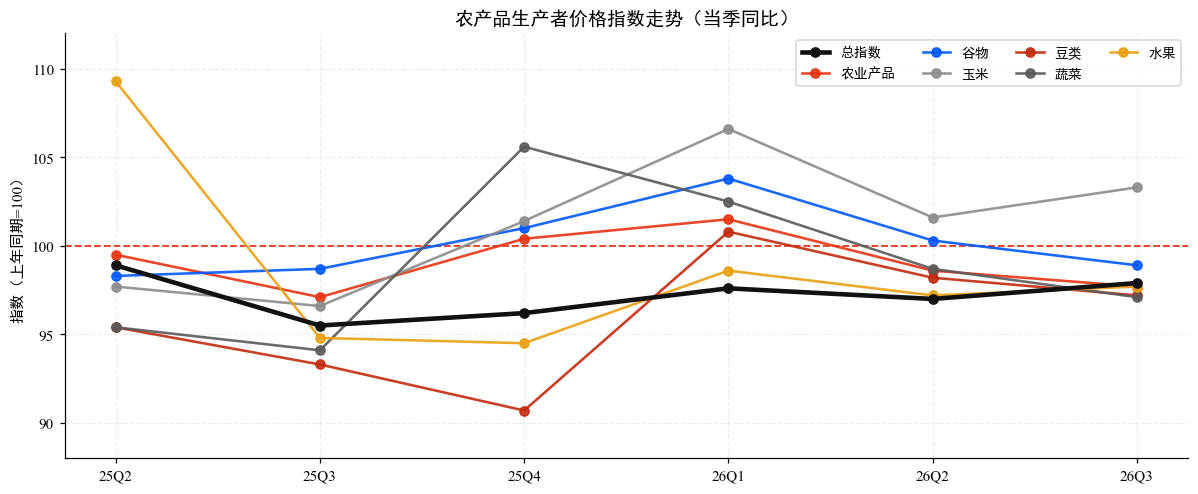

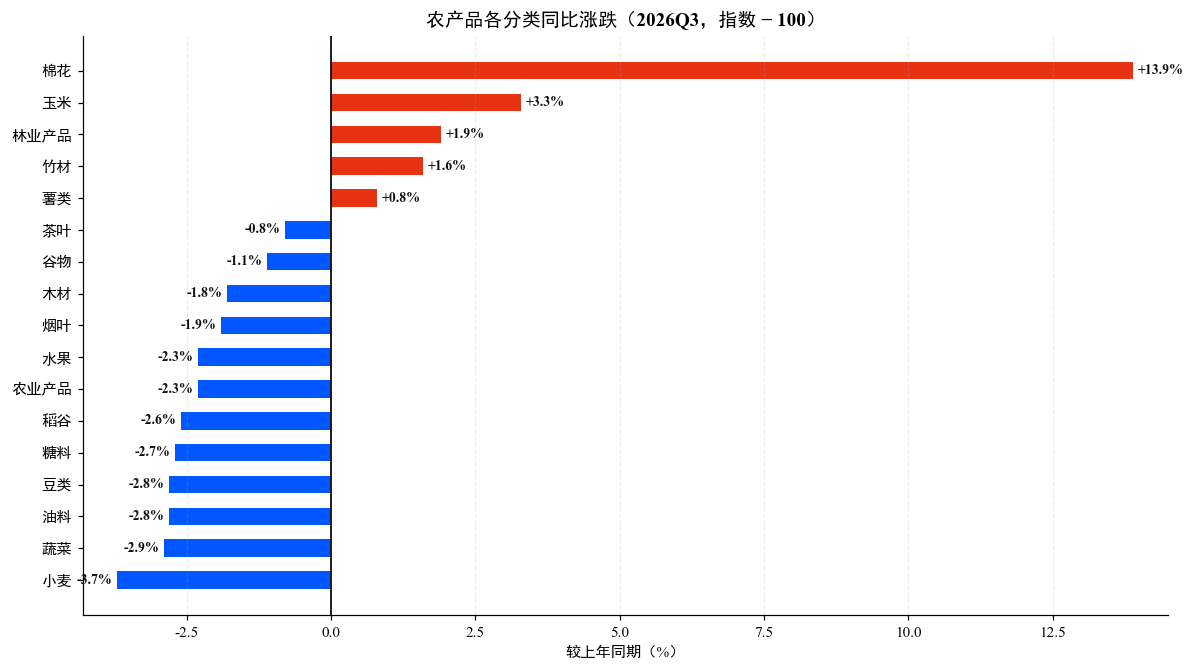

In [2]:
# 表 1：农产品生产者价格指数
quarters, rows = load_table('农产品生产者价格指数（上年同期=100）.csv')
labels = [short_q(q) for q in quarters]
x = np.arange(len(quarters))

total = nanify(col(rows, '农产品生产者价格指数当季值'))
# 主要品类指标前缀（注意"农业产品"为"生产者价格指数"，其余为"生产价格指数"）
MAIN_PREFIX = [
    ('农业产品', '农业产品生产者价格指数当季值'),
    ('谷物', '谷物生产价格指数当季值'),
    ('玉米', '玉米生产价格指数当季值'),
    ('豆类', '豆类生产价格指数当季值'),
    ('蔬菜', '蔬菜生产价格指数当季值'),
    ('水果', '水果生产价格指数当季值'),
]
main_vals = {c: nanify(col(rows, p)) for c, p in MAIN_PREFIX}

# 图 1：多线折线图
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(x, total, 'o-', color=INK, lw=3, label='总指数', zorder=5)
for i, (c, p) in enumerate(MAIN_PREFIX):
    ax.plot(x, main_vals[c], 'o-', color=LINE_COLORS[(i + 1) % len(LINE_COLORS)],
            lw=1.7, label=c, alpha=0.9)
baseline(ax)
ax.set_xticks(x, labels)
ax.set_ylabel('指数（上年同期=100）')
ax.set_ylim(88, 112)
ax.set_title('农产品生产者价格指数走势（当季同比）')
ax.legend(ncol=4, fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

# 图 2：最新季度分类涨跌发散条形图（注意"农业产品"为"生产者价格指数"）
latest = len(quarters) - 1
CATS_ALL = [('农业产品', '农业产品生产者价格指数当季值'),
            ('谷物', '谷物生产价格指数当季值'),
            ('小麦', '小麦生产价格指数当季值'),
            ('稻谷', '稻谷生产价格指数当季值'),
            ('玉米', '玉米生产价格指数当季值'),
            ('豆类', '豆类生产价格指数当季值'),
            ('薯类', '薯类生产价格指数当季值'),
            ('油料', '油料生产价格指数当季值'),
            ('棉花', '棉花生产价格指数当季值'),
            ('糖料', '糖料生产价格指数当季值'),
            ('烟叶', '烟叶生产价格指数当季值'),
            ('蔬菜', '蔬菜生产价格指数当季值'),
            ('水果', '水果生产价格指数当季值'),
            ('茶叶', '茶叶生产价格指数当季值'),
            ('林业产品', '林业产品生产价格指数当季值'),
            ('木材', '木材生产价格指数当季值'),
            ('竹材', '竹材生产价格指数当季值')]
names, devs = [], []
for c, p in CATS_ALL:
    v = col(rows, p)[latest]
    if v is not None:
        names.append(c)
        devs.append(v - 100)
fig, ax = plt.subplots(figsize=(11, 6.2))
dev_bars(ax, names, devs,
         title=f'农产品各分类同比涨跌（{quarters[latest]}，指数 − 100）')
plt.tight_layout()
plt.show()

## 表 2 · 固定资产投资价格指数_当季（-2018 旧口径）

**图 1** 多线折线图：总指数与主要分项走势（2017Q4—2018Q4，100 基准线）；
**图 2** 发散横向条形图：2018Q4 各分项同比涨跌。

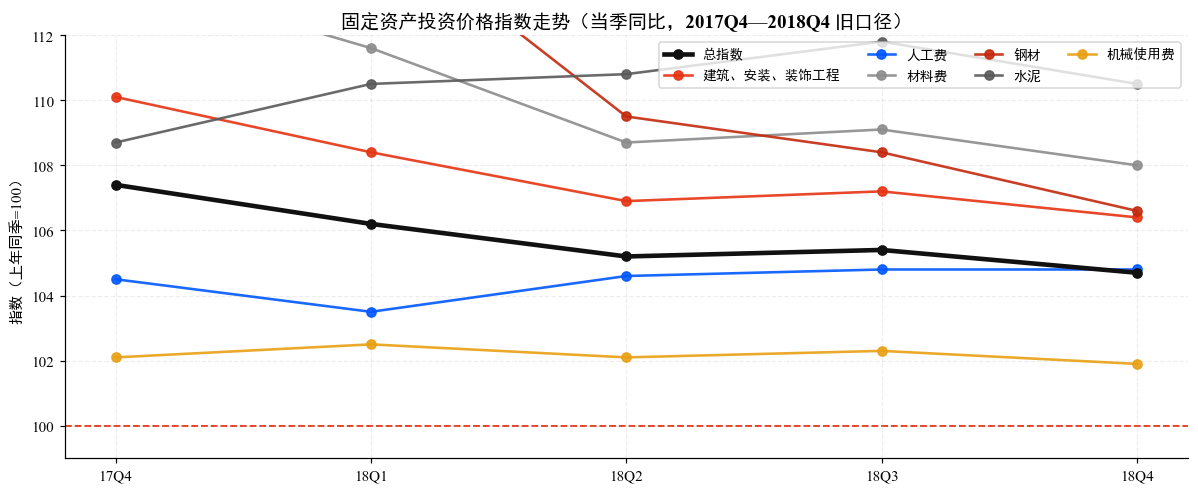

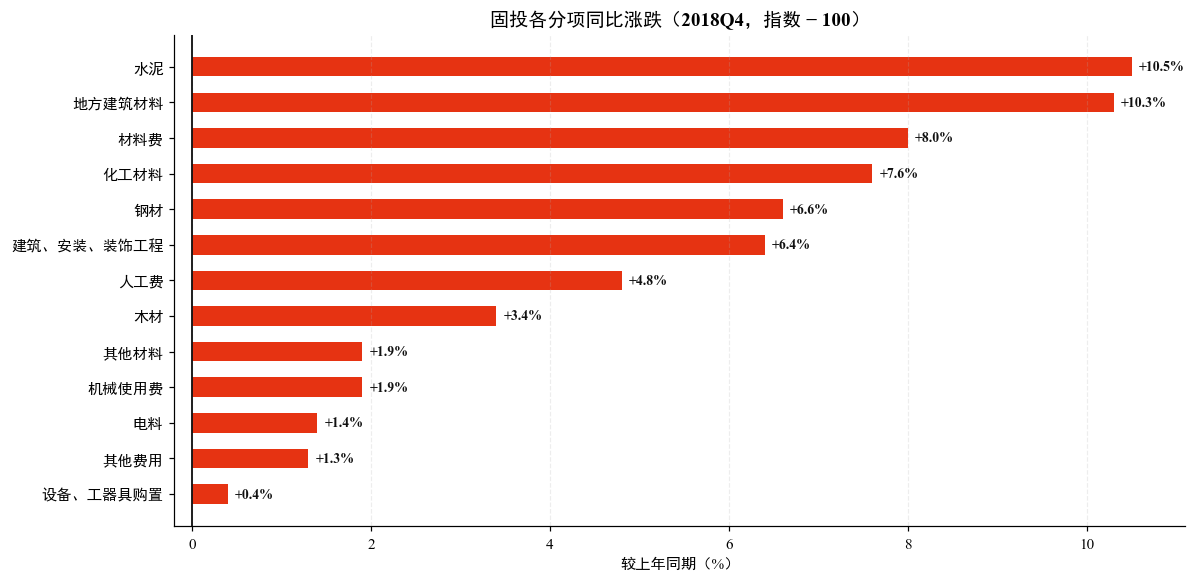

In [3]:
# 表 2：固定资产投资价格指数_当季（旧口径）
quarters, rows = load_table('固定资产投资价格指数_当季（上年同季=100） (-2018).csv')
labels = [short_q(q) for q in quarters]
x = np.arange(len(quarters))

total = col(rows, '固定资产投资价格指数当季值')
SUB = ['建筑、安装、装饰工程', '人工费', '材料费', '钢材', '水泥', '机械使用费']
sub_vals = {c: col(rows, f'{c}价格指数当季值') for c in SUB}

# 图 1：多线折线图
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(x, total, 'o-', color=INK, lw=3, label='总指数', zorder=5)
for i, c in enumerate(SUB):
    ax.plot(x, sub_vals[c], 'o-', color=LINE_COLORS[(i + 1) % len(LINE_COLORS)],
            lw=1.7, label=c, alpha=0.9)
baseline(ax)
ax.set_xticks(x, labels)
ax.set_ylabel('指数（上年同季=100）')
ax.set_ylim(99, 112)
ax.set_title('固定资产投资价格指数走势（当季同比，2017Q4—2018Q4 旧口径）')
ax.legend(ncol=4, fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

# 图 2：最新季度（2018Q4）分类涨跌发散条形图
latest = len(quarters) - 1
CATS_OLD = ['设备、工器具购置', '建筑、安装、装饰工程', '人工费', '材料费', '钢材', '木材',
            '水泥', '地方建筑材料', '化工材料', '电料', '其他材料', '机械使用费', '其他费用']
names, devs = [], []
for c in CATS_OLD:
    v = col(rows, f'{c}价格指数当季值')[latest]
    names.append(c)
    devs.append(v - 100)
fig, ax = plt.subplots(figsize=(11, 5.4))
dev_bars(ax, names, devs, title=f'固投各分项同比涨跌（{quarters[latest]}，指数 − 100）')
plt.tight_layout()
plt.show()

## 表 3 · 固定资产投资价格指数_当季（2019- 新口径）

**图 1** 小倍数折线图：四个主要分项 2019 年逐季走势（共享量纲、便于对比形态）；
**图 2** 发散横向条形图：2019Q4 各分项同比涨跌。

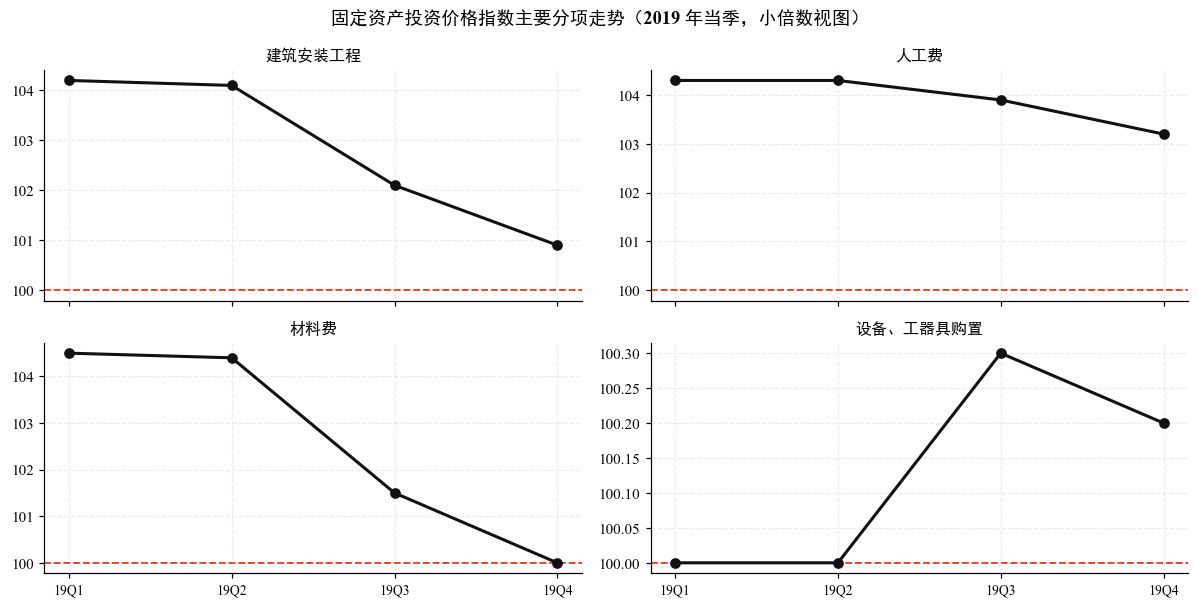

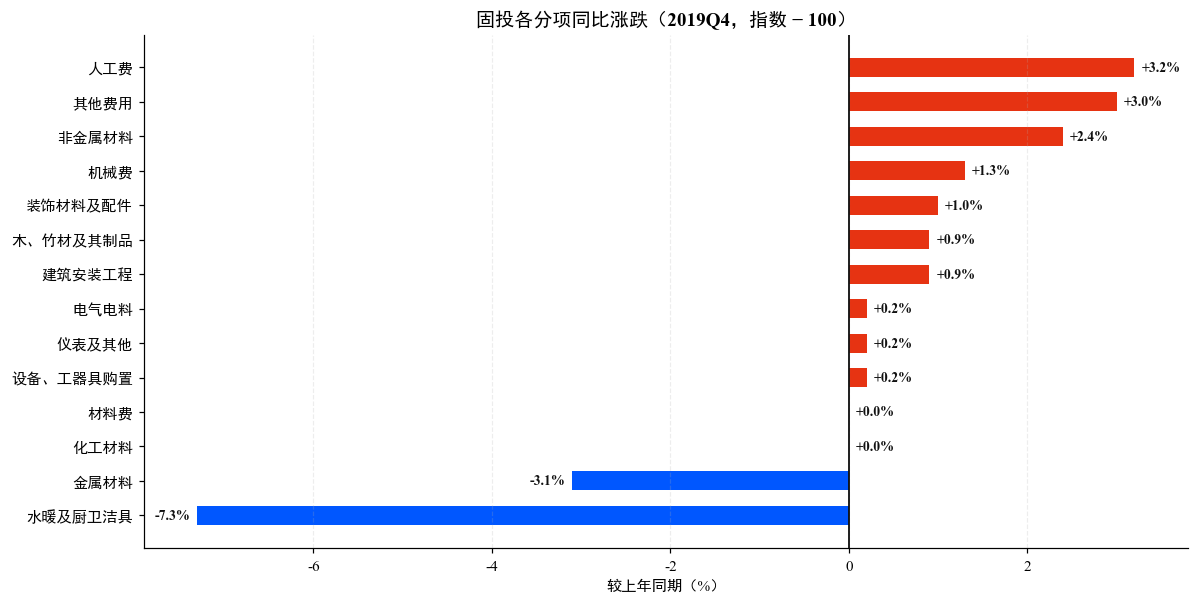

In [4]:
# 表 3：固定资产投资价格指数_当季（新口径）
quarters, rows = load_table('固定资产投资价格指数_当季（上年同季=100） (2019-).csv')
labels = [short_q(q) for q in quarters]
x = np.arange(len(quarters))

total = col(rows, '固定资产投资价格指数当季值')
SUB2 = ['建筑安装工程', '人工费', '材料费', '设备、工器具购置']

# 图 1：小倍数折线图（2×2）
sel = ['建筑安装工程', '人工费', '材料费', '设备、工器具购置']
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True)
for ax, c in zip(axes.flat, sel):
    vals = col(rows, f'{c}价格指数当季值')
    ax.plot(x, vals, 'o-', color=INK, lw=2)
    baseline(ax)
    ax.set_title(c, fontsize=10.5)
    ax.set_xticks(x, labels, fontsize=9)
fig.suptitle('固定资产投资价格指数主要分项走势（2019 年当季，小倍数视图）', fontweight='bold')
plt.tight_layout()
plt.show()

# 图 2：最新季度（2019Q4）分类涨跌发散条形图
latest = len(quarters) - 1
CATS_NEW = ['建筑安装工程', '人工费', '材料费', '金属材料', '非金属材料', '化工材料',
            '木、竹材及其制品', '装饰材料及配件', '水暖及厨卫洁具', '电气电料',
            '仪表及其他', '机械费', '设备、工器具购置', '其他费用']
names, devs = [], []
for c in CATS_NEW:
    v = col(rows, f'{c}价格指数当季值')[latest]
    names.append(c)
    devs.append(v - 100)
fig, ax = plt.subplots(figsize=(11, 5.6))
dev_bars(ax, names, devs, title=f'固投各分项同比涨跌（{quarters[latest]}，指数 − 100）')
plt.tight_layout()
plt.show()

## 表 4 · 固定资产投资价格指数_累计值（-2018 旧口径）

**图 1** 面积折线图：总指数累计走势（含 100 基准线）与人工费 / 材料费 / 钢材三大分项；
**图 2** 发散横向条形图：2018Q4 累计同比涨跌。

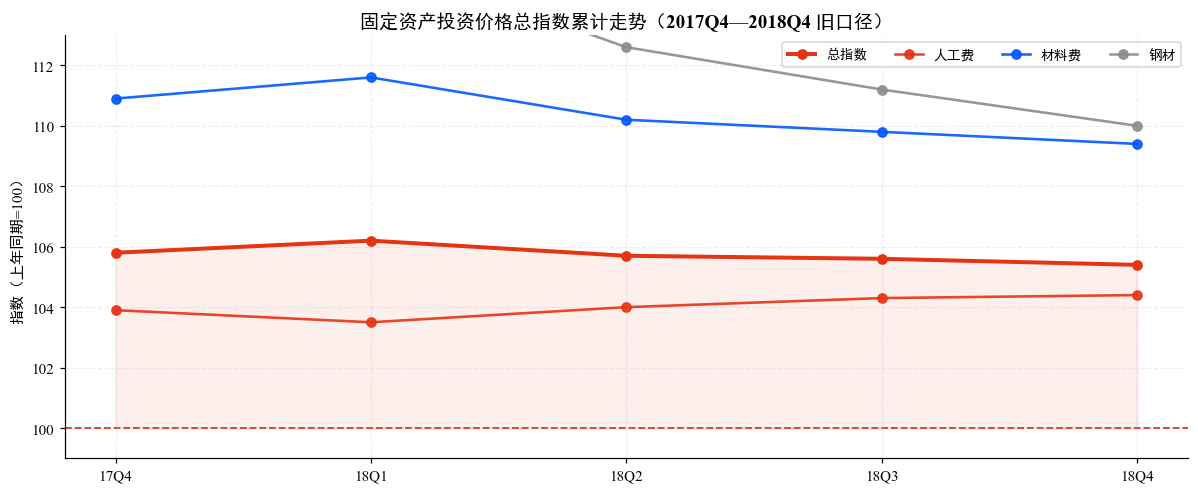

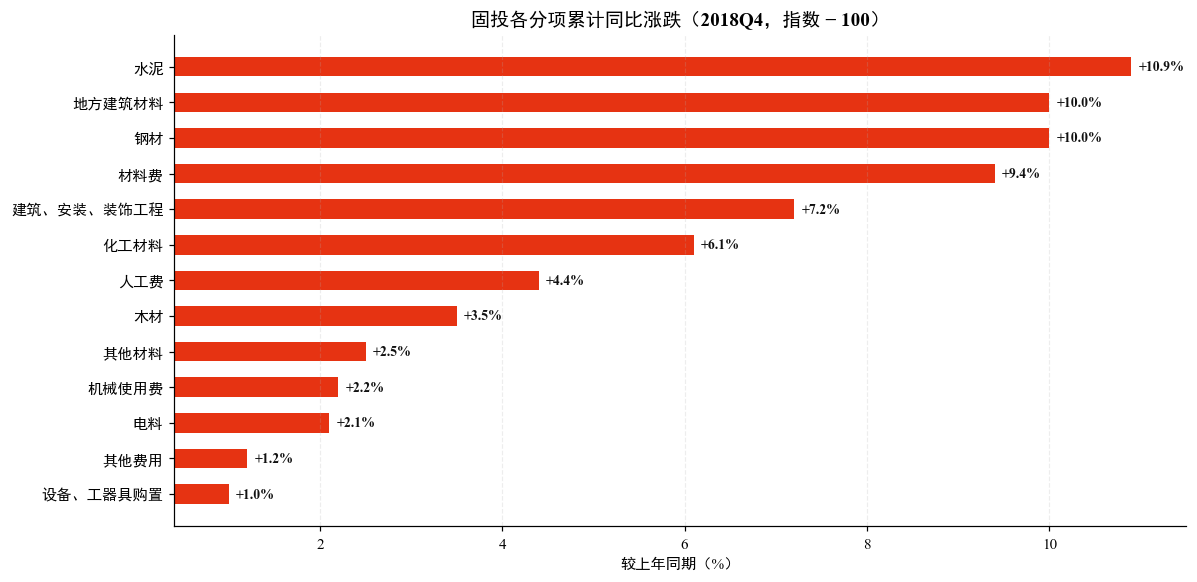

In [5]:
# 表 4：固定资产投资价格指数_累计值（旧口径）
quarters, rows = load_table('固定资产投资价格指数_累计值（上年同期=100） (-2018).csv')
labels = [short_q(q) for q in quarters]
x = np.arange(len(quarters))

total = col(rows, '固定资产投资价格指数累计值')

# 图 1：总指数面积图 + 三大分项多线
SUB3 = ['人工费', '材料费', '钢材']
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(x, total, 'o-', color=RED, lw=2.6, label='总指数', zorder=5)
ax.fill_between(x, 100, total, color=RED, alpha=0.08)
baseline(ax)
for i, c in enumerate(SUB3):
    ax.plot(x, col(rows, f'{c}价格指数累计值'), 'o-', color=LINE_COLORS[(i + 1) % len(LINE_COLORS)],
            lw=1.7, label=c, alpha=0.9)
ax.set_xticks(x, labels)
ax.set_ylabel('指数（上年同期=100）')
ax.set_ylim(99, 113)
ax.set_title('固定资产投资价格总指数累计走势（2017Q4—2018Q4 旧口径）')
ax.legend(ncol=4, fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

# 图 2：最新季度（2018Q4）累计涨跌发散条形图
latest = len(quarters) - 1
CATS_OLD = ['设备、工器具购置', '建筑、安装、装饰工程', '人工费', '材料费', '钢材', '木材',
            '水泥', '地方建筑材料', '化工材料', '电料', '其他材料', '机械使用费', '其他费用']
names, devs = [], []
for c in CATS_OLD:
    v = col(rows, f'{c}价格指数累计值')[latest]
    names.append(c)
    devs.append(v - 100)
fig, ax = plt.subplots(figsize=(11, 5.4))
dev_bars(ax, names, devs, title=f'固投各分项累计同比涨跌（{quarters[latest]}，指数 − 100）')
plt.tight_layout()
plt.show()

## 表 5 · 固定资产投资价格指数_累计（2019- 新口径）

**图 1** 阶梯折线图：总指数累计走势（step 线，100 基准线）；
**图 2** 棒棒糖图（lollipop）：2019Q4 各分项累计同比涨跌。

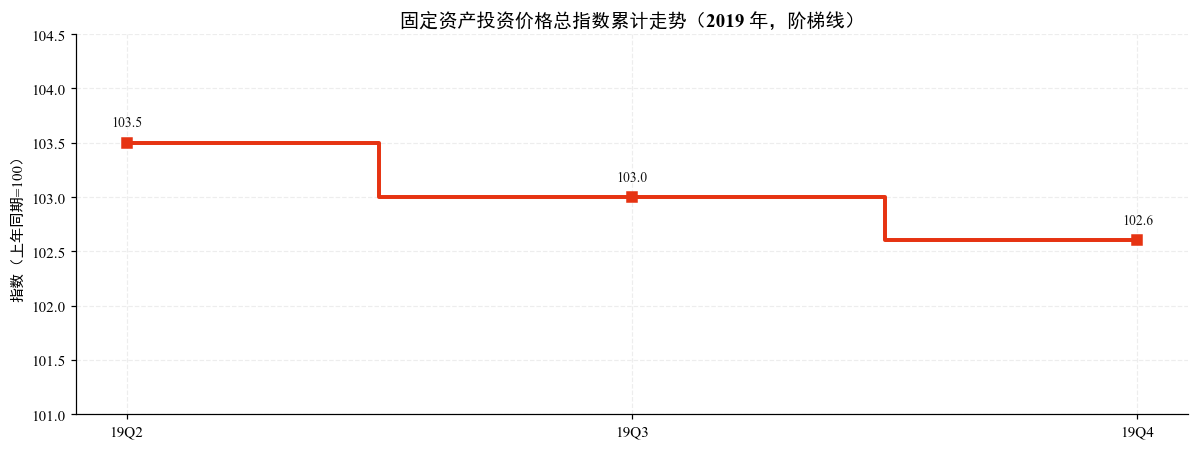

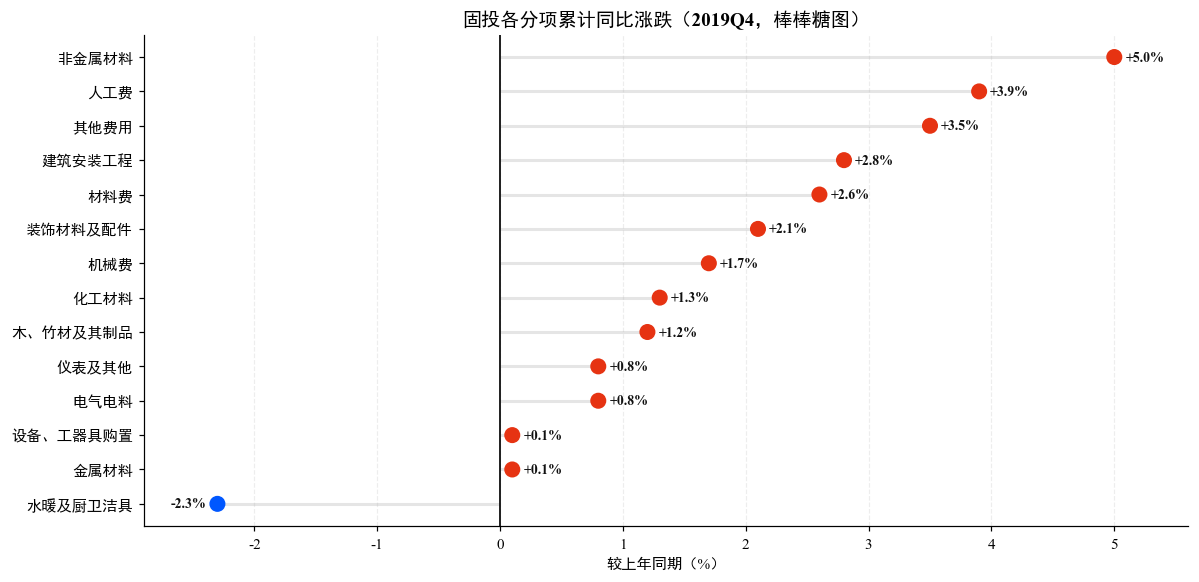

In [6]:
# 表 5：固定资产投资价格指数_累计（新口径）
quarters, rows = load_table('固定资产投资价格指数_累计（上年同期=100） (2019-).csv')
labels = [short_q(q) for q in quarters]
x = np.arange(len(quarters))

total = col(rows, '固定资产投资价格指数累计值')

# 图 1：总指数阶梯折线图
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.step(x, total, where='mid', color=RED, lw=2.6, label='总指数（阶梯线）')
ax.plot(x, total, 's', color=RED, ms=6)
baseline(ax)
for xi, v in zip(x, total):
    ax.text(xi, v + 0.15, f'{v:.1f}', ha='center', fontsize=9, color=INK)
ax.set_xticks(x, labels)
ax.set_ylabel('指数（上年同期=100）')
ax.set_ylim(101, 104.5)
ax.set_title('固定资产投资价格总指数累计走势（2019 年，阶梯线）')
plt.tight_layout()
plt.show()

# 图 2：最新季度（2019Q4）棒棒糖图
latest = len(quarters) - 1
CATS_NEW = ['建筑安装工程', '人工费', '材料费', '金属材料', '非金属材料', '化工材料',
            '木、竹材及其制品', '装饰材料及配件', '水暖及厨卫洁具', '电气电料',
            '仪表及其他', '机械费', '设备、工器具购置', '其他费用']
pairs = sorted([(c, col(rows, f'{c}价格指数累计值')[latest] - 100) for c in CATS_NEW],
               key=lambda t: t[1])
names = [p[0] for p in pairs]
devs = [p[1] for p in pairs]
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.hlines(names, 0, devs, color=HAIR, lw=2, zorder=1)
ax.scatter(devs, names, s=90, color=[RED if d >= 0 else BLUE for d in devs], zorder=3)
for n, d in zip(names, devs):
    ax.text(d + (0.09 if d >= 0 else -0.09), n, f'{d:+.1f}%', va='center',
            ha='left' if d >= 0 else 'right', fontsize=9, fontweight='bold', color=INK)
ax.axvline(0, color=INK, lw=1.2)
ax.set_xlim(min(devs) - 0.6, max(devs) + 0.6)
ax.set_xlabel('较上年同期（%）')
ax.set_title(f'固投各分项累计同比涨跌（{quarters[latest]}，棒棒糖图）')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()